<a href="https://colab.research.google.com/github/keathana2007/DEEP-LEARNING/blob/main/dl_skill_6_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import files

uploaded = files.upload()


Saving Skill6_Traffic_Dataset.zip to Skill6_Traffic_Dataset.zip


In [2]:

import zipfile
import os

zip_file = list(uploaded.keys())[0]

extract_path = "/content/traffic_dataset"

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path))


Dataset extracted successfully!
['annotations', 'images']


In [3]:

import os
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

print("All libraries imported successfully!")


All libraries imported successfully!


In [4]:

# Find the COCO JSON annotation file

json_files = []

for root, dirs, files_list in os.walk(extract_path):
    for file in files_list:
        if file.endswith(".json"):
            json_files.append(os.path.join(root, file))

print("JSON files found:")
for f in json_files:
    print(f)


JSON files found:
/content/traffic_dataset/annotations/instances.json


In [5]:

annotation_path = json_files[0]

with open(annotation_path, 'r') as f:
    data = json.load(f)

images = data['images']
annotations = data['annotations']
categories = data['categories']

print("Total Images:", len(images))
print("Total Annotations:", len(annotations))
print("Total Categories:", len(categories))


Total Images: 12
Total Annotations: 36
Total Categories: 4


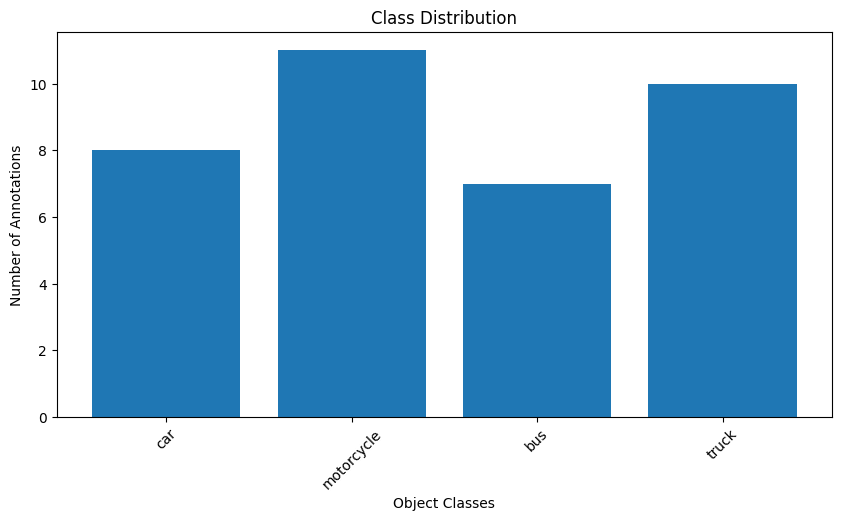

In [6]:

from collections import Counter

category_names = {
    cat['id']: cat['name']
    for cat in categories
}

class_counts = Counter(
    ann['category_id']
    for ann in annotations
)

class_names = [
    category_names[cid]
    for cid in class_counts
]

class_values = list(class_counts.values())

plt.figure(figsize=(10,5))

plt.bar(class_names, class_values)

plt.title("Class Distribution")
plt.xlabel("Object Classes")
plt.ylabel("Number of Annotations")
plt.xticks(rotation=45)

plt.show()


In [7]:

# Find images in the dataset

image_paths = []

for root, dirs, files_list in os.walk(extract_path):
    for file in files_list:
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            image_paths.append(os.path.join(root, file))

print("Total image files found:", len(image_paths))


Total image files found: 12


In [8]:

image_results = []

for path in image_paths:
    try:
        img = cv2.imread(path)

        if img is None:
            continue

        height, width = img.shape[:2]

        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        brightness = np.mean(gray)

        blur_score = cv2.Laplacian(
            gray, cv2.CV_64F
        ).var()

        image_results.append({
            'Image': os.path.basename(path),
            'Width': width,
            'Height': height,
            'Brightness': brightness,
            'Blur Score': blur_score
        })

    except Exception as e:
        print("Problem:", path)

quality_df = pd.DataFrame(image_results)

print(quality_df.head(10))


            Image  Width  Height  Brightness  Blur Score
0  traffic_02.jpg    640     400  140.626547  412.438094
1  traffic_09.jpg    640     400  139.385164  325.979000
2  traffic_06.jpg    640     400  142.125188  468.827117
3  traffic_10.jpg    640     400  141.637012  468.032988
4  traffic_08.jpg    640     400  137.837711  357.218258
5  traffic_07.jpg    640     400  142.356957  407.875152
6  traffic_01.jpg    640     400  136.842871  358.894500
7  traffic_04.jpg    640     400  139.809066  424.524812
8  traffic_05.jpg    640     400  140.835945  360.051367
9  traffic_03.jpg    640     400  141.512578  341.893203


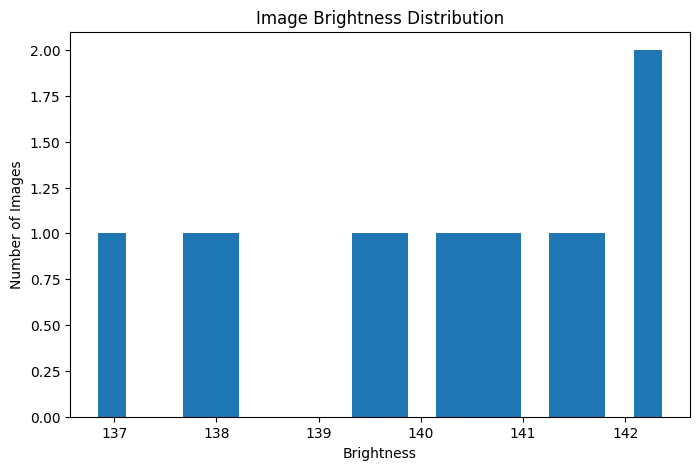

In [9]:

plt.figure(figsize=(8,5))

plt.hist(quality_df['Brightness'], bins=20)

plt.title("Image Brightness Distribution")
plt.xlabel("Brightness")
plt.ylabel("Number of Images")

plt.show()


In [10]:

image_info = {
    img['id']: img for img in images
}

valid_count = 0
invalid_count = 0

for ann in annotations:

    img = image_info.get(ann['image_id'])

    if img is None:
        invalid_count += 1
        continue

    x, y, w, h = ann['bbox']

    img_width = img['width']
    img_height = img['height']

    if (w > 0 and h > 0 and
        x >= 0 and y >= 0 and
        x + w <= img_width and
        y + h <= img_height):

        valid_count += 1

    else:
        invalid_count += 1

print("Valid Annotations:", valid_count)
print("Invalid Annotations:", invalid_count)


Valid Annotations: 36
Invalid Annotations: 0


In [11]:

print("===== SKILL 6 DATASET AUDIT REPORT =====")

print("Total Images:", len(images))
print("Total Image Files Found:", len(image_paths))
print("Total Categories:", len(categories))
print("Total Annotations:", len(annotations))

print("Valid Annotations:", valid_count)
print("Invalid Annotations:", invalid_count)

print("\nDataset Audit Completed Successfully!")


===== SKILL 6 DATASET AUDIT REPORT =====
Total Images: 12
Total Image Files Found: 12
Total Categories: 4
Total Annotations: 36
Valid Annotations: 36
Invalid Annotations: 0

Dataset Audit Completed Successfully!
